In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)

url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
print("Missing values:")
display(df.isna().sum())

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


Missing values:


lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [2]:
categorical = [
    "lead_source", "industry", "employment_status", "location"
]

numerical = [
    "annual_income", "number_of_courses_viewed",
    "interaction_count", "lead_score"
]

features = categorical + numerical

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# Separate the target from the input features
y_train = df_train["converted"].to_numpy()
y_val = df_val["converted"].to_numpy()
y_test = df_test["converted"].to_numpy()

df_train = df_train[features].copy()
df_val = df_val[features].copy()
df_test = df_test[features].copy()

print("Training:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)
print("Remaining missing values:", df[features].isna().sum().sum())

Training: (3000, 8)
Validation: (1000, 8)
Test: (1000, 8)
Remaining missing values: 0


In [3]:
results_q1 = []

for feature in numerical:
    scores = df_train[feature]
    original_auc = roc_auc_score(y_train, scores)

    # Reverse the direction if AUC is below 0.5
    if original_auc < 0.5:
        scores = -scores

    auc = roc_auc_score(y_train, scores)

    results_q1.append({
        "feature": feature,
        "original_auc": original_auc,
        "adjusted_auc": auc,
    })

results_q1 = pd.DataFrame(results_q1)
display(
    results_q1.sort_values("adjusted_auc", ascending=False)
)

,feature,original_auc,adjusted_auc
3,lead_score,0.788225,0.788225
2,interaction_count,0.764920,0.764920
1,number_of_courses_viewed,0.722989,0.722989
0,annual_income,0.608198,0.608198


In [5]:
# Encode categorical features and keep numerical features
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train.to_dict("records"))
X_val = dv.transform(df_val.to_dict("records"))

# Train with the exact homework parameters
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000,
)

model.fit(X_train, y_train)

# AUC uses predicted probabilities
y_pred_proba = model.predict_proba(X_val)[:, 1]

auc_q2 = roc_auc_score(y_val, y_pred_proba)

print("Validation AUC:", auc_q2)

Validation AUC: 0.7318222288173319


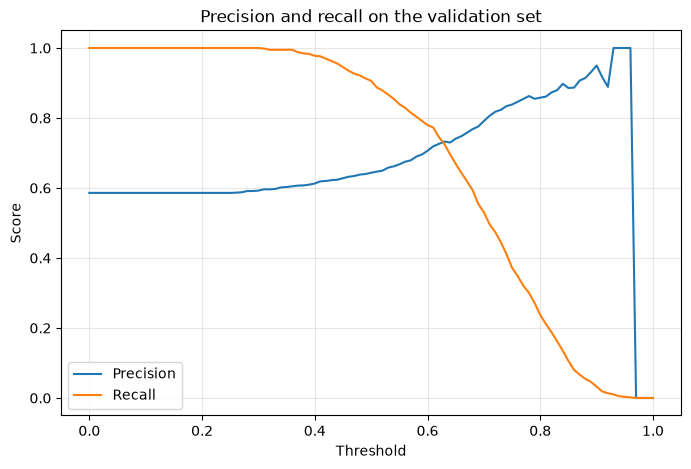

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64

In [7]:
results_thresholds = []

for threshold in np.linspace(0, 1, 101):
    predictions = y_pred_proba >= threshold

    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )

    results_thresholds.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
    })

df_thresholds = pd.DataFrame(results_thresholds)

# Plot precision and recall
plt.figure(figsize=(8, 5))
plt.plot(
    df_thresholds["threshold"],
    df_thresholds["precision"],
    label="Precision",
)
plt.plot(
    df_thresholds["threshold"],
    df_thresholds["recall"],
    label="Recall",
)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and recall on the validation set")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Ignore thresholds where both metrics are zero
valid = df_thresholds[
    (df_thresholds["precision"] > 0)
    | (df_thresholds["recall"] > 0)
].copy()

valid["difference"] = (
    valid["precision"] - valid["recall"]
).abs()

best_q3 = valid.loc[valid["difference"].idxmin()]

display(best_q3)

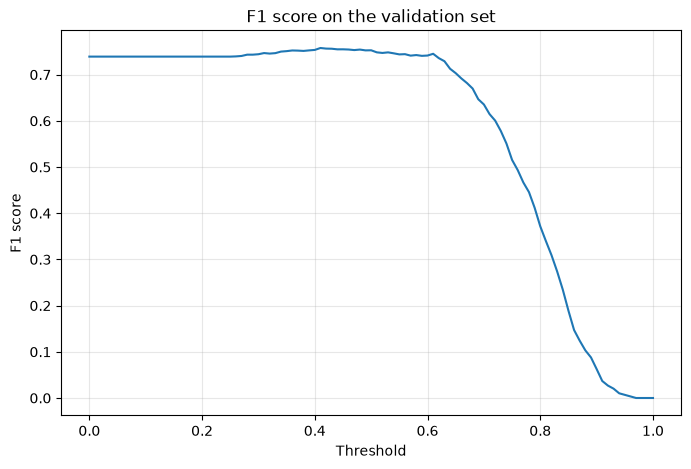

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64

In [9]:
df_thresholds["f1"] = [
    f1_score(
        y_val,
        y_pred_proba >= threshold,
        zero_division=0,
    )
    for threshold in df_thresholds["threshold"]
]

best_q4 = df_thresholds.loc[df_thresholds["f1"].idxmax()]

plt.figure(figsize=(8, 5))
plt.plot(df_thresholds["threshold"], df_thresholds["f1"])
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("F1 score on the validation set")
plt.grid(alpha=0.3)
plt.show()

display(best_q4)

In [11]:
def evaluate_cv(C=1.0):
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1,
    )

    scores = []

    for fold, (train_idx, val_idx) in enumerate(
        kfold.split(df_full_train), start=1
    ):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        y_fold_train = fold_train["converted"].to_numpy()
        y_fold_val = fold_val["converted"].to_numpy()

        # Fit a fresh encoder using only this fold's training data
        dv_fold = DictVectorizer(sparse=False)

        X_fold_train = dv_fold.fit_transform(
            fold_train[features].to_dict("records")
        )
        X_fold_val = dv_fold.transform(
            fold_val[features].to_dict("records")
        )

        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000,
        )
        model_fold.fit(X_fold_train, y_fold_train)

        probabilities = model_fold.predict_proba(X_fold_val)[:, 1]
        auc = roc_auc_score(y_fold_val, probabilities)

        scores.append(auc)
        print(f"Fold {fold}: AUC = {auc:.6f}")

    return np.array(scores)


scores_q5 = evaluate_cv(C=1.0)

Fold 1: AUC = 0.730560
Fold 2: AUC = 0.729573
Fold 3: AUC = 0.736343
Fold 4: AUC = 0.741245
Fold 5: AUC = 0.720914


In [13]:
results_q6 = []

for c in [0.000001, 0.001, 1]:
    print(f"\nC = {c}")

    scores = evaluate_cv(C=c)

    results_q6.append({
        "C": c,
        "mean_auc": round(float(np.mean(scores)), 3),
        "std_auc": round(float(np.std(scores)), 3),
    })

results_q6 = pd.DataFrame(results_q6)

# Highest mean AUC, then lowest std, then smallest C
results_q6 = results_q6.sort_values(
    ["mean_auc", "std_auc", "C"],
    ascending=[False, True, True],
)

display(results_q6)


C = 1e-06
Fold 1: AUC = 0.594100
Fold 2: AUC = 0.640214
Fold 3: AUC = 0.600157
Fold 4: AUC = 0.636447
Fold 5: AUC = 0.612753

C = 0.001
Fold 1: AUC = 0.750435
Fold 2: AUC = 0.747533
Fold 3: AUC = 0.758354
Fold 4: AUC = 0.758413
Fold 5: AUC = 0.731126

C = 1
Fold 1: AUC = 0.730560
Fold 2: AUC = 0.729573
Fold 3: AUC = 0.736343
Fold 4: AUC = 0.741245
Fold 5: AUC = 0.720914


,C,mean_auc,std_auc
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
0,0.000001,0.617,0.019
